Importa as Bibilhotecas

In [ ]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

Carrega o Dataset

In [ ]:
df = pd.read_csv('kc_house_data.csv')
df = df.rename(columns={
    "date": "data_venda",
    "price": "preco",
    "bedrooms": "quartos",
    "bathrooms": "banheiros",
    "sqft_living": "area_habitavel",
    "sqft_lot": "area_terreno",
    "floors": "andares",
    "waterfront": "frente_agua",
    "view": "vista",
    "condition": "condicao",
    "grade": "padrao_construcao",
    "sqft_above": "area_acima_solo",
    "sqft_basement": "area_porao",
    "yr_built": "ano_construcao",
    "yr_renovated": "ano_reforma",
    "zipcode": "codigo_postal",
    "lat": "latitude",
    "long": "longitude",
    "sqft_living15": "area_habitavel_vizinhos",
    "sqft_lot15": "area_terreno_vizinhos"
})

1° Etapa (Análise Exploratória)

In [ ]:
# Estrutura do DataFrame

In [ ]:
print("Número de linhas e colunas:", df.shape)

Número de linhas e colunas: (21613, 21)


In [ ]:
df.head()

,id,data_venda,preco,quartos,banheiros,area_habitavel,area_terreno,andares,frente_agua,vista,...,padrao_construcao,area_acima_solo,area_porao,ano_construcao,ano_reforma,codigo_postal,latitude,longitude,area_habitavel_vizinhos,area_terreno_vizinhos
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
df.nunique()

id                         21436
data_venda                   372
preco                       4028
quartos                       13
banheiros                     30
area_habitavel              1038
area_terreno                9782
andares                        6
frente_agua                    2
vista                          5
condicao                       5
padrao_construcao             12
area_acima_solo              946
area_porao                   306
ano_construcao               116
ano_reforma                   70
codigo_postal                 70
latitude                    5034
longitude                    752
area_habitavel_vizinhos      777
area_terreno_vizinhos       8689
dtype: int64

In [ ]:
print('Número de valores nulos:', df.isnull().sum().sum())

Número de valores nulos: 0


In [ ]:
# Análise dos Quartis e Outliers

In [ ]:
print("Média de Preço:", df['preco'].mean())

print("1º Quartil de Preço:", df['preco'].quantile(0.25))
print("Mediana de Preço:", df['preco'].median())
print("3º Quartil de Preço:", df['preco'].quantile(0.75))

Média de Preço: 540088.1417665294
1º Quartil de Preço: 321950.0
Mediana de Preço: 450000.0
3º Quartil de Preço: 645000.0


In [ ]:
diq = df['preco'].quantile(0.75) - df['preco'].quantile(0.25)
limite_inferior = df['preco'].quantile(0.25) - 1.5 * diq
limite_superior = df['preco'].quantile(0.75) + 1.5 * diq

print("Limite Inferior:", limite_inferior)
print("Limite Superior:", limite_superior)

print("Número de Outliers:", df[(df['preco'] < limite_inferior) | (df['preco'] > limite_superior)].shape[0])

Limite Inferior: -162625.0
Limite Superior: 1129575.0
Número de Outliers: 1146


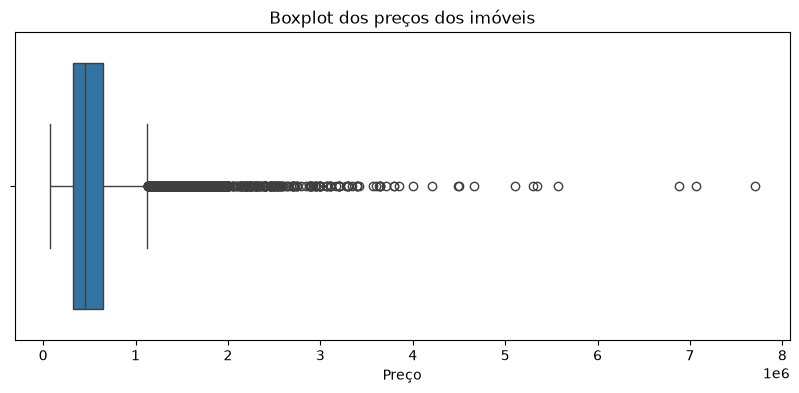

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["preco"])

plt.title("Boxplot dos preços dos imóveis")
plt.xlabel("Preço")
plt.show()

In [ ]:
df.sort_values(by='preco', ascending=False).head(10)

,id,data_venda,preco,quartos,banheiros,area_habitavel,area_terreno,andares,frente_agua,vista,...,padrao_construcao,area_acima_solo,area_porao,ano_construcao,ano_reforma,codigo_postal,latitude,longitude,area_habitavel_vizinhos,area_terreno_vizinhos
7252,6762700020,20141013T000000,7700000.0,6,8.00,12050,27600,2.5,0,3,...,13,8570,3480,1910,1987,98102,47.6298,-122.323,3940,8800
3914,9808700762,20140611T000000,7062500.0,5,4.50,10040,37325,2.0,1,2,...,11,7680,2360,1940,2001,98004,47.6500,-122.214,3930,25449
9254,9208900037,20140919T000000,6885000.0,6,7.75,9890,31374,2.0,0,4,...,13,8860,1030,2001,0,98039,47.6305,-122.240,4540,42730
4411,2470100110,20140804T000000,5570000.0,5,5.75,9200,35069,2.0,0,0,...,13,6200,3000,2001,0,98039,47.6289,-122.233,3560,24345
1448,8907500070,20150413T000000,5350000.0,5,5.00,8000,23985,2.0,0,4,...,12,6720,1280,2009,0,98004,47.6232,-122.220,4600,21750
1315,7558700030,20150413T000000,5300000.0,6,6.00,7390,24829,2.0,1,4,...,12,5000,2390,1991,0,98040,47.5631,-122.210,4320,24619
1164,1247600105,20141020T000000,5110800.0,5,5.25,8010,45517,2.0,1,4,...,12,5990,2020,1999,0,98033,47.6767,-122.211,3430,26788
8092,1924059029,20140617T000000,4668000.0,5,6.75,9640,13068,1.0,1,4,...,12,4820,4820,1983,2009,98040,47.5570,-122.210,3270,10454
2626,7738500731,20140815T000000,4500000.0,5,5.50,6640,40014,2.0,1,4,...,12,6350,290,2004,0,98155,47.7493,-122.280,3030,23408
8638,3835500195,20140618T000000,4489000.0,4,3.00,6430,27517,2.0,0,0,...,12,6430,0,2001,0,98004,47.6208,-122.219,3720,14592


In [ ]:
# Distribuição e Variância dos Preços

In [ ]:
print(f"Variância: {df['preco'].var():.2f}")
print(f"Desvio padrão: {df['preco'].std():.2f}")
print(f"Coeficiente de variação: {df['preco'].std() / df['preco'].mean() * 100:.2f}%")

Variância: 134782378397.25
Desvio padrão: 367127.20
Coeficiente de variação: 67.98%


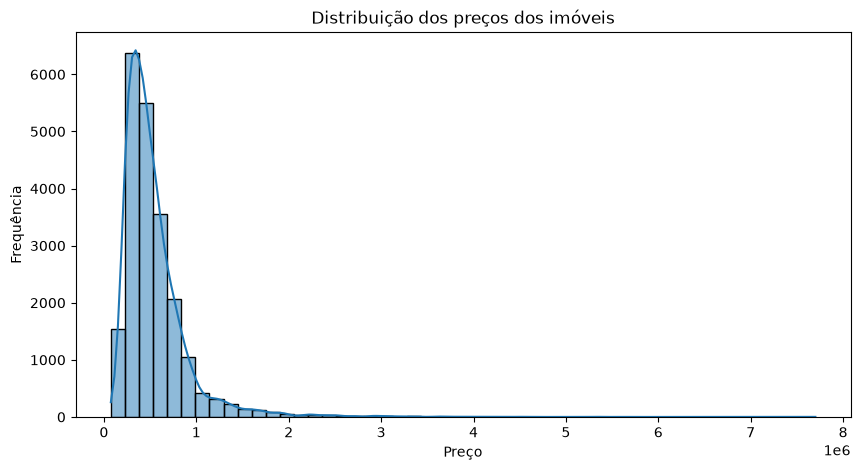

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df["preco"], bins=50, kde=True)

plt.title("Distribuição dos preços dos imóveis")
plt.xlabel("Preço")
plt.ylabel("Frequência")
plt.show()

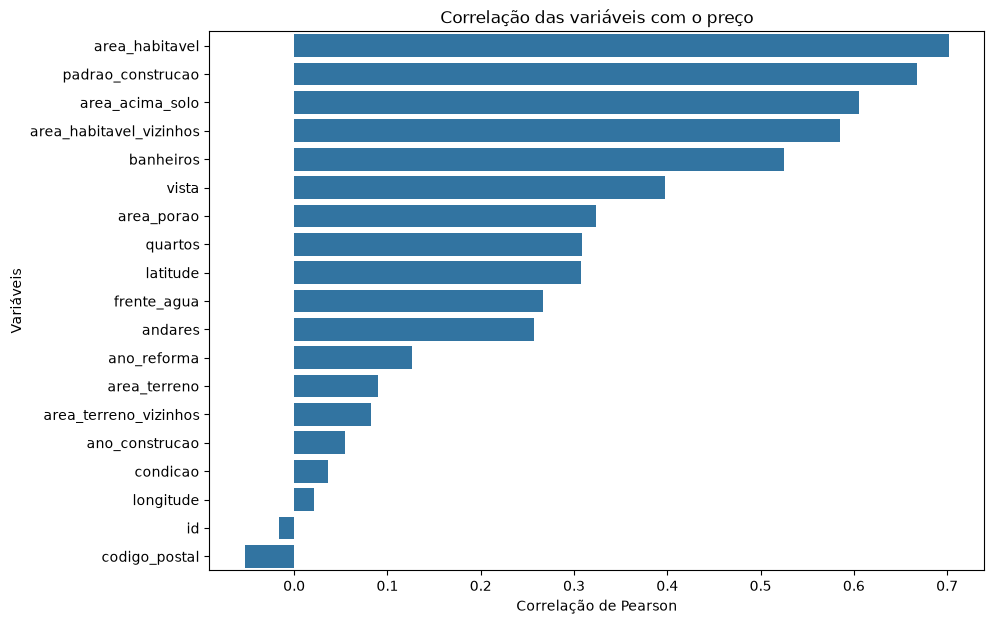

In [ ]:
correlacoes = df.select_dtypes(include="number").corr()["preco"]
correlacoes = correlacoes.drop("preco").sort_values(ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(x=correlacoes.values, y=correlacoes.index)

plt.title("Correlação das variáveis com o preço")
plt.xlabel("Correlação de Pearson")
plt.ylabel("Variáveis")
plt.show()

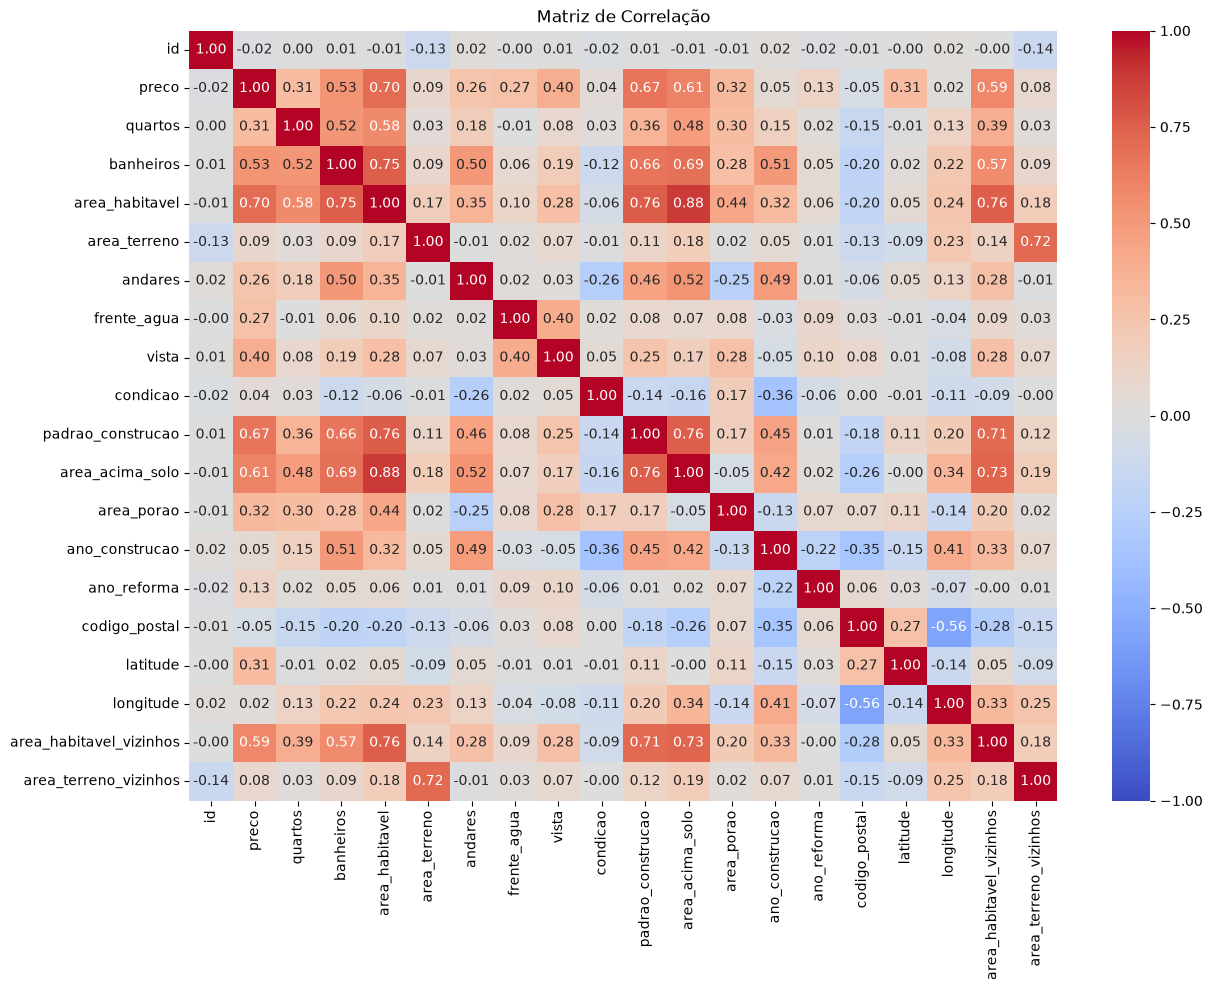

In [ ]:
correlacao = df.select_dtypes(include="number").corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de Correlação")
plt.show()

Conclusão

O dataset não possui valores nulos, oque ajuda para a nossa análise.

Apesar de haver uma quantidade grande de outliers, faz sentido olhando os 10 imóveis com maior preço, uma área habitavel gigantesca com alto padrão. Desta forma, vamos testar de ambas as maneiras, mas estamos inclinados a manter os outliers.

Várias variavéis tem relação positiva com o preço, porém algums delas tem correlação direta com as outras, oque pode as tornar redundantes, desta forma acreditamos que as melhores variavéis para os modelos são:

area_habitavel: tem a maior relação positiva.

padrao_construcao: tem a segunda maior relacao positiva e apesar de uma correlação alta com a area_habitavel, conceitualmente elas não tem relação direta, uma casa com pouca area_habitavel pode ter um auto padrao_construcao, e o iverso também.

area_habitavel_vizinhos: tem a quarta maior relação positiva e apesar de uma correlação alta com a area_habitavel e padrao_construcao, conceitualmente elas não tem relaçao direta com a do imovél avaliado, mas pode indicar um padrão de um condominio por exemplo.